In [1]:
from config_structured_documents_graph import Settings
from dotenv import load_dotenv

load_dotenv()
settings = Settings()

In [13]:
import base64
import fitz
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage
from langgraph.graph import END, START, StateGraph, MessagesState

vlm = ChatOpenAI(
    model="Qwen/Qwen2-VL-7B-Instruct-AWQ",
    base_url="https://skillet-appealing-broken.ngrok-free.dev/v1",
    api_key="not-needed",
    max_tokens=2048,
)

def first_node(state: MessagesState) -> MessagesState:
    _document = fitz.open("API-600.pdf")

    received_text = []
    for page_number in range(len(_document)):

        first_page = _document[page_number]
        pix = first_page.get_pixmap(dpi=160)


        image_bytes = pix.tobytes()
        image_base64 = base64.b64encode(image_bytes).decode("utf-8")

        message = HumanMessage(content=[
            {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{image_base64}"}},
            {"type": "text", "text": "Извлеки текст с этой страницы, сохраняя структуру, таблицы оформи как markdown"}
        ])

        response = vlm.invoke([message])
        received_text.append(response)

    with open("output_markdown.md", "w", encoding="utf-8") as f:
        for msg in received_text:
            f.write(msg.content)
            f.write("\n\n")
    return {"messages": received_text}

builder = StateGraph(MessagesState)
builder.add_node(first_node)
builder.add_edge(START, "first_node")
builder.add_edge("first_node", END)
graph = builder.compile()

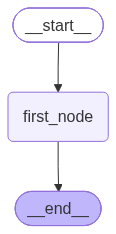

In [3]:
from IPython.display import display, Image

display(Image(graph.get_graph().draw_mermaid_png()))

In [14]:
inv = graph.invoke({"messages": []})

for message in inv["messages"]:
    message.pretty_print()


# Steel Gate Valves—Flanged and Butt-welding Ends, Bolted Bonnets

## API STANDARD 600
**THIRTEENTH EDITION, JANUARY 2015**

**EFFECTIVE DATE: JULY 2015**

---

**Copyright American Petroleum Institute**
**Provided by IHS under license with API**
**No reproduction or networking permitted without license from IHS**



# Special Notes

API publications necessarily address problems of a general nature. With respect to particular circumstances, local, state, and federal laws and regulations should be reviewed.

Neither API nor any of API's employees, subcontractors, consultants, committees, or other assignees make any warranty or representation, either express or implied, with respect to the accuracy, completeness, or usefulness of the information contained herein, or assume any liability or responsibility for any use, or the results of such use, of any information or process disclosed in this publication. Neither API nor any of API's employees, subcontractors, consultants, or other assignees represent that use of this publication would not infringe upon privately owned rights.

API publications may be used by anyone desiring to do so. Every effort has been made by the Institute to assure the accuracy and reliability of the data contained in them; however, the Institute makes no representation, warranty, or guarantee in connection with this publication and hereby expressly disclaims any liability or responsibility for loss or damage resulting from its use or for the violation of any authorities having jurisdiction with which this publication may conflict.

API publications are published to facilitate the broad availability of proven, sound engineering and operating practices. These publications are not intended to obviate the need for applying sound engineering judgment regarding when and where these publications should be utilized. The formulation and publication of API publications is not intended in any way to inhibit anyone from using any other practices.

Any manufacturer marking equipment or materials in conformance with the marking requirements of an API standard is solely responsible for complying with all the applicable requirements of that standard. API does not represent, warrant, or guarantee that such products do in fact conform to the applicable API standard.

Users of this Standard should not rely exclusively on the information contained in this document. Sound business, scientific, engineering, and safety judgment should be used in employing the information contained herein.



# Foreword

Nothing contained in any API publication is to be construed as granting any right, by implication or otherwise, for the manufacture, sale, or use of any method, apparatus, or product covered by letters patent. Neither should anything contained in the publication be construed as insuring anyone against liability for infringement of letters patent.

Shall: As used in a standard, “shall” denotes a minimum requirement in order to conform to the specification.

Should: As used in a standard, “should” denotes a recommendation or that which is advised but not required in order to conform to the specification.

This document was produced under API standardization procedures that ensure appropriate notification and participation in the developmental process and is designated as an API standard. Questions concerning the interpretation of the content of this publication or comments and questions concerning the procedures under which this publication was developed should be directed in writing to the Director of Standards, American Petroleum Institute, 1220 L Street, NW, Washington, DC 20005. Requests for permission to reproduce or translate all or any part of the material published herein should also be addressed to the director.

Generally, API standards are reviewed and revised, reaffirmed, or withdrawn at least every five years. A one-time extension of up to two years may be added to this review cycle. Status of the publication can be ascertained from the API Standards Department, telephone (202) 682-8000. A catalog of API publications and materials is published annually by API, 1220 L Street, NW, Washington, DC 20005.

Suggested revisions are invited and should be submitted to the Standards Department, API, 1220 L Street, NW, Washington, DC 20005, standards@api.org.


Copyright American Petroleum Institute
Provided by IHS under license with API
No reproduction or networking permitted without license from IHS


# Contents

## 1 Scope
1

## 2 Normative References
1

## 3 Terms and Definitions
2

## 4 Pressure/Temperature Ratings
3

## 5 Design
3
### 5.1 Body Wall Thickness
3
### 5.2 Bonnet Wall Thickness
4
### 5.3 Body Dimensions
4
### 5.4 Bonnet
8
### 5.5 Bonnet-to-body Joint
8
### 5.6 Gate
9
### 5.7 Yoke
10
### 5.8 Stem and Stem Nut
11
### 5.9 Packing and Packing Box
14
### 5.10 Bolting
15
### 5.11 Operation
15
### 5.12 Bypasses and Other Auxiliary Connections
15

## 6 Materials
16
### 6.1 Materials Other Than Trim Materials
16
### 6.2 Trim
17

## 7 Testing, Inspection and Examination
17
### 7.1 Inspection and Examination
17
### 7.2 Pressure Tests
17
### 7.3 Repairs of Defects
17

## 8 Marking
21
### 8.1 General
21
### 8.2 Marking for Unidirectional Valves
21

## 9 Preparation for Shipment
21
### 9.1 Coatings
21
### 9.2 Openings
21
### 9.3 Gate Position
21
### 9.4 Stem Packing
22
### 9.5 Packaging
22
### 9.6 Purchase Order Information
22

### Annex A (informative) API Monogram Program Use of the API Monogram by Licensees
23

### Annex B (normative) Information to be Specified by the Purchaser
27

### Annex C (informative) Identification of Valve Terms
29

### Annex D (informative) Valve Material Combinations
30

### Bibliography 33



# Contents

## Figures

| Figure | Title | Page |
| --- | --- | --- |
| 1 | Identification of Terms | 4 |
| 2 | Types of Valve Gates | 10 |
| 3 | Wear Travel | 11 |
| C.1 | Valve Nomenclature | 29 |

## Tables

| Table | Title | Page |
| --- | --- | --- |
| 1 | Minimum Wall Thickness for Body and Bonnet | 5 |
| 2 | Post Weld Heat Treatment for Flange to Body Weld | 6 |
| 3 | Minimum Inside Diameter for Sizes DN 800 to DN 1050 (NPS 32 to NPS 42) in Classes 150 and 300 | 7 |
| 4 | Minimum Wear Travel and Maximum Stem Projection | 11 |
| 5 | Minimum Stem Diameter | 12 |
| 5A | Permitted Undertolerance | 13 |
| 6 | Nominal Radial Width of Packing | 14 |
| 7 | Materials for Parts | 16 |
| 8 | Nominal Seating Surface, Stem and Backseat Bushing or Weld-deposit Materials and Hardness | 18 |
| 9 | Trim Numbers and Alternative Trim Numbers | 21 |
| D.1 | Material Combinations for Group 1 Body, Bonnet and Cover Materials | 30 |
| D.2 | Material Combinations for Group 2 Body to Bonnet Materials | 31 |
| D.3 | Alternative Body to Bonnet Bolting Materials | 32 |



# Steel Gate Valves—Flanged and Butt-welding Ends, Bolted Bonnets

## 1 Scope

This standard specifies the requirements for a heavy-duty series of bolted bonnet steel gate valves for petroleum refinery and related applications where corrosion, erosion, and other service conditions would indicate a need for full port openings, heavy wall sections, and large stem diameters.

This standard sets forth the requirements for the following gate valve features:

- bolted bonnet,
- outside screw and yoke,
- rising stems,
- non-rising handwheels,
- single or double gate,
- wedge or parallel seating,
- metallic seating surfaces,
- flanged or butt-welding ends.

It covers valves of the nominal pipe sizes DN:

- 25, 32, 40, 50, 65, 80, 100, 150, 200, 250, 300, 350, 400, 450, 500, 600, 650, 700, 750, 800, 850, 900, 950, 1000, 1050;

corresponding to nominal pipe sizes NPS:

- 1, 1 1/4, 1 1/2, 2, 2 1/2, 3, 4, 6, 8, 10, 12, 14, 16, 18, 20, 24, 26, 28, 30, 32, 34, 36, 38, 40, 42;

and applies to pressure class designations:

- 150, 300, 600, 900, 1500, 2500.

If product is supplied bearing the API Monogram and manufactured at a facility licensed by API, the requirements of Annex A apply.

## 2 Normative References

The following referenced documents are indispensable for the application of this document. For dated references, only the edition cited applies. For undated references, the latest edition of the referenced document (including any amendments) applies.

API Standard 598, Valve Inspection and Testing

API Standard 624, Type Testing of Rising Stem Valves Equipped with Graphite Packing for Fugitive Emissions

ASME B1.1 1, Unified Inch Screw Threads (UN and UNR Thread Form)

1 ASME International, 2 Park Avenue, New York, New York 10016-5990, www.asme.org.



# API STANDARD 600

## ASME B1.5, Acme Screw Threads

## ASME B1.8, Stub Acme Screw Threads

## ASME B1.12, Class 5 Interference—Fit Thread

## ASME B1.13M, Metric Screw Threads: M Profile

## ASME B16.5, Pipe Flanges and Flanged Fittings NPS 1/2 through NPS 24 Metric/Inch

## ASME B16.10, Face-to Face and End-to-End Dimensions of Valves

## ASME B16.25, Buttwelding Ends

## ASME B16.34, Valves—Flanged, Threaded and Welding End

## ASME B16.47, Large Diameter Steel Flanges, NPS 26 Through NPS 60 Metric/Inch Standard

## ASME B18.2.2, Nuts for General Applications: Machine Screw Nuts, Hex, Square, Hex Flange, and Coupling Nuts (Inch Series)

## ASME B18.2.6M, Metric Fasteners for Use in Structural Applications

## ASME B31.3, Process Piping

## ISO 5210 2, Industrial valves—Multi-turn valve actuator attachments

## ISO 5752, Metal valves for use in flanged pipe systems—Face-to-face and centre-to-face dimensions

## ISO 15649, Petroleum and natural gas industries—Piping

## MSS SP-91 3, Guidelines for Manual Operation of Valves

## MSS SP-102, Multi-Turn Valve Actuator Attachment—Flange and Driving Component Dimensions and Performance Characteristics

## MSS SP-144, Pressure Seal Bonnet Valves

### 3. Terms and Definitions

For the purposes of this document, the following definitions apply.

#### 3.1 Class

An alphanumeric designation that is used for reference purposes relating to valve pressure/temperature capability, taking into account valve material mechanical properties and valve dimensional characteristics. It comprises “Class” followed by a dimensionless whole number. The number following “Class” does not represent a measurable value and is not used for calculation purposes except where specified in this standard. The allowable pressure for a valve


# STEEL GATE VALVES—FLANGED AND BUTT-WELDING ENDS, BOLTED BONNETS

## 3.2 DN
An alpha numeric designation of size that is common for components used in a piping system, used for reference purposes, comprising the letters “DN” followed by a dimensionless number indirectly related to the physical size of the bore or outside diameter of the end connection as appropriate. The dimensionless number following “DN” does not represent a measurable value and is not used for calculation purposes except where specified.

## 3.3 NPS
An alpha numeric designation of size that is common for components used in a piping system, used for reference purposes, comprising the letters “NPS” followed by a dimensionless number indirectly related to the physical size of the bore or outside diameter of the end connection as appropriate. The dimensionless number may be used as a valve size identifier without the prefix “NPS.” The dimensionless size identification number does not represent a measurable value and is not used for calculation purposes.

## 3.4 Shell
Comprised of the body, bonnet and body-bonnet bolting which constitute the pressure boundary of an API 600 valve.

## 4 Pressure/Temperature Ratings
### 4.1 Pressure/temperature ratings shall be in accordance with those specified in the tables of ASME B16.34 for standard class for the applicable material specification and the applicable class.

### 4.2 Restrictions of temperature and concurrent pressure, or pressure and concurrent temperature, (e.g. those imposed by special soft seals or special trim materials), shall be marked on the valve identification plate (see Section 8).

### 4.3 The temperature for a corresponding pressure rating is the maximum temperature of the pressure-containing shell of the valve. In general, this temperature is the same as that of the contained fluid. The use of a pressure rating corresponding to a temperature other than that of the contained fluid is the responsibility of the user.

### 4.4 For temperatures below the lowest temperature listed in the pressure/temperature tables, the service pressure shall be no greater than the pressure for the lowest listed temperature. The use of valves at lower temperatures is the responsibility of the user. Consideration should be given to the loss of ductility and impact strength of many materials at low temperature.

### 4.5 Double seated valves, in some design configurations, may be capable of trapping liquid in the center cavity of the valve when in the closed position. If subjected to an increase in temperature, an excessive build-up of pressure can occur, which may result in a pressure boundary failure. Where such a condition is possible, it is the responsibility of the user to provide or require to be provided, means in design, installation, or operating procedure, to assure that the pressure in the valve does not exceed that allowed by this standard for the resultant temperature.

## 5 Design
### 5.1 Body Wall Thickness
#### 5.1.1  A valve body schematic is shown as Figure 1. The minimum body wall thickness, \( t_m \), at the time of manufacture shall be as given in Table 1, except as indicated in 5.1.2 for butt-welding valve ends. Additional metal thickness needed for assembly stresses, stress concentrations, and shapes other than circular shall be determined by individual manufacturers, since these factors vary widely.


# API STANDARD 600

## Figure 1—Identification of Terms

### 5.1.2
The weld end preparation in butt-welding end valves (see 5.3.2) shall not reduce the body wall thickness to less than the values specified in 5.1.1 within a region closer than \( t_m \) to the outside surface of the body neck, measured along the run direction. The transition to the weld preparation shall be gradual and the section shall be essentially circular through the entire length of the transition. Sharp discontinuities or abrupt changes in section in areas that infringe into the transition shall be avoided, except that test collars or bands, either welded or integral, are allowed. In no case shall the thickness be less than \( 0.77 t_m \) at a distance of \( 2 t_m \) from the weld end.

### 5.2 Bonnet Wall Thickness
The minimum bonnet wall thickness at the time of manufacture, except for the neck extension that contains the packing, shall be \( t_m \) as given in Table 1. For the neck extension, the local minimum wall thickness shall be based on the local diameter, e.g. the inside diameter of the stem bore or packing box bore, and shall be in accordance with the valve body neck rules of ASME B16.34.

### 5.3 Body Dimensions
#### 5.3.1 Flanged Ends
##### 5.3.1.1
Body end flanges shall comply with the dimensional requirements of ASME B16.5 for sizes up to and including DN 600 (NPS 24). For sizes over DN 600 (NPS 24), body end flanges shall comply with the dimensional requirements of ASME B16.47 Series A or Series B as specified by the purchaser. Unless otherwise specified, raised face end flanges shall be provided. The purchaser may specify a flange facing finish other than that specified in ASME B16.5 or ASME B16.47, as applicable.

##### 5.3.1.2
Face-to-face dimensions shall be in accordance with ASME B16.10 or ISO 5752. For sizes not listed, dimensions shall be as agreed to between purchaser and manufacturer. Body end flanges and bonnet flanges shall be cast or forged integral with the body. However, flanges may be attached by welding when approved by the purchaser.



# Table 1—Minimum Wall Thickness for Body and Bonnet

| Class Designation | 150 | 300 | 600 | 900 | 1500 | 2500 | Class Designation |
|---|---|---|---|---|---|---|---|
| Nominal Size DN | | | | | | | Nominal Pipe Size NPS |
| 25 | 6.4 (0.25) | 6.4 (0.25) | 7.9 (0.31) | 12.7 (0.50) | 12.7 (0.50) | 15.0 (0.59) | 1 |
| 32 | 6.4 (0.25) | 6.4 (0.25) | 8.6 (0.34) | 14.2 (0.56) | 14.2 (0.56) | 17.5 (0.69) | 1 1/4 |
| 40 | 6.4 (0.25) | 7.9 (0.31) | 9.4 (0.37) | 15.0 (0.59) | 15.0 (0.59) | 19.1 (0.75) | 1 1/2 |
| 50 | 8.6 (0.34) | 9.7 (0.38) | 11.2 (0.44) | 19.1 (0.75) | 19.1 (0.75) | 22.4 (0.88) | 2 |
| 65 | 9.7 (0.38) | 11.2 (0.44) | 11.9 (0.47) | 22.4 (0.88) | 22.4 (0.88) | 25.4 (1.00) | 2 1/2 |
| 80 | 10.4 (0.41) | 11.9 (0.47) | 12.7 (0.50) | 19.1 (0.75) | 23.9 (0.94) | 30.2 (1.19) | 3 |
| 100 | 11.2 (0.44) | 12.7 (0.50) | 16.0 (0.63) | 21.3 (0.84) | 28.7 (1.13) | 35.8 (1.41) | 4 |
| 150 | 11.9 (0.47) | 16.0 (0.63) | 19.1 (0.75) | 26.2 (1.03) | 38.1 (1.50) | 48.5 (1.91) | 6 |
| 200 | 12.7 (0.50) | 17.5 (0.69) | 25.4 (1.00) | 31.8 (1.25) | 47.8 (1.88) | 62.0 (2.44) | 8 |
| 250 | 14.2 (0.56) | 19.1 (0.75) | 28.7 (1.13) | 36.6 (1.44) | 57.2 (2.25) | 67.6 (2.66) | 10 |
| 300 | 16.0 (0.63) | 20.6 (0.81) | 31.8 (1.25) | 42.2 (1.66) | 66.8 (2.63


# API STANDARD 600

## 5.3.1.2.1
Welding a flange to a valve body shall be by full penetration butt-welding. Unless otherwise specified, attachment weld shall conform to ASME B31.3 or ISO 15649 for normal fluid service, including weld quality acceptance criteria and qualifications for the weld procedure and welder or welding operator. Heat treatment shall be performed in accordance with Table 2.

## 5.3.1.2.2
Integral or other alignment rings (centering backing rings) used to facilitate welding shall be removed after the weld is completed.

## 5.3.2 Butt-welding Ends

### 5.3.2.1
Butt-welding ends for valve sizes greater than NPS 2 shall conform to the requirements of ASME B16.25 for the bore specified for use without backing rings. Butt-welding ends for valves DN 50 (NPS 2) and smaller shall conform to the requirement of API 602. Conversion of a flanged end valve to a butt-welding valve is not permitted except by agreement between the purchaser and manufacturer.

The chemical composition of carbon steel welding ends shall meet the following requirements unless otherwise agreed:

- the carbon content shall not exceed 0.23 % by mass;
- the carbon equivalent, CE, shall not exceed 0.43 as determined by the following formula:

\[ CE = C + \frac{Mn}{6} + \frac{(Cr + Mo + V)}{5} + \frac{(Ni + Cu)}{15} \]

where

- C is weight % Carbon
- Mn is weight % Manganese.

### Table 2—Post Weld Heat Treatment for Flange to Body Weld

| Material | Thickness \( t \) mm (in.) | Temperature Range \( ^{\circ}C \left( ^{\circ}F \right) \) | Holding Time/ Thickness minutes/millimeter (hours/inch) | Weld Hardness HBN Max |
|---|---|---|---|---|
| Carbon steels | \( t > 19 \) (0.75) | 593 to 649 (1100 to 1200) | 2.4 (1) minimum time 1 hr. | — |
| Alloy steels: | \( t > 13 \) (0.50) | 704 to 746 (1300 to 1375) | 2.4 (1) minimum time 2 hr. | 225 |
| \( 2^{1/4} \% \leq Cr \leq 10 \% \) | All | 704 to 760 (1300 to 1400) | 2.4 (1) minimum time 2 hr. | 241 |
| Nickel alloy steels | \( t > 19 \) (0.75) | 593 to 635 (1100 to 1175) | 1.2 (1/2) minimum time 1 hr. | — |
| Austenitic steels \( ^a \) \( ^b \) | All | solution anneal per the material specification |
| Other materials | All | per the material specification |

---

\( ^a \) Thickness, \( t \), is the greater thickness of the pieces being joined by welding.

\( ^b \) Except when materials being welded are L-Grades or stabilized grades.



# Steel Gate Valves—Flanged and Butt-welding Ends, Bolted Bonnets

## 7

| Cr | is weight % Chromium |
|---|----------------------|
| Mo | is weight % Molybdenum |
| V | is weight % Vanadium |
| Ni | is weight % Nickel |
| Cu | is weight % Copper |

### 5.3.2.2 End-to-end dimensions for butt-welding end class designated valves shall be in accordance with ASME B16.10, unless otherwise specified by the purchaser.

### 5.3.3 Body Seats

#### 5.3.3.1 The inside diameter of the seat opening shall not be less than that specified below:
- for all Classes in sizes up to DN 600 (NPS 24), ASME B16.34;
- for Classes 150 and 300 in sizes DN 650 to DN 750 (NPS 26 to NPS 30), ASME B16.34;
- for Classes 150 and 300 in sizes DN 800 to 1050 (NPS 32 to NPS 42), refer to Table 3.

#### 5.3.3.2 Seating surfaces shall be integral or faced with weld metal. Finished thickness of any facing material shall be not less than 1.6 mm (0.06 in.).

#### 5.3.3.3 Integral body seats are permitted in austenitic stainless steel valves. When an austenitic stainless steel or a hardfacing material is used for the body seat, this material may be weld-deposited directly on the valve body.

#### 5.3.3.4 Where separate seat rings are provided, they shall be shoulder or bottom seated, and either threaded or seal welded in place, except that for DN ≤ 50 (NPS ≤ 2) rolled or pressed in seat rings may be used. Threaded seat rings shall be seal welded; tack welding or stitch welding is not permitted.

#### 5.3.3.5 Body seat rings shall have adequate seating area surface and shall have edges equipped with a radius or chamfer as necessary, to prevent galling or any other damage to the disc when the valve is operated against pressure.

#### 5.3.3.6 Sealing compounds or greases shall not be used when assembling seat rings; however, a light lubricant having a viscosity no greater than kerosene may be used to prevent galling of mating threaded surfaces.

### Table 3—Minimum Inside Diameter for Sizes DN 800 to DN 1050 (NPS 32 to NPS 42) in Classes 150 and 300

| DN | NPS | Classes 150 and 300 |
|---|---|---|
| 800 | 32 | 779 | 30.67 |
| 850 | 34 | 830 | 32.68 |
| 900 | 36 | 874 | 34.41 |
| 950 | 38 | 925 | 36.42 |
| 1000 | 40 | 976 | 38.43 |
| 1050 | 42 | 1020 | 40.16 |



# Bonnet

## 5.4.1 When designing the stem, gland, lantern ring (if supplied) and backseat, the manufacturer shall take into account stem guiding and the prevention of packing extrusion.

## 5.4.2 The bonnet shall include a conical or spherical stem backseat in one of the following forms:

- a bushing positively secured against coming loose, i.e. not relying on friction;
- an integral surface in the case of an austenitic stainless steel valve;
- an austenitic stainless steel or hardfaced weld deposit that is a minimum of 1.6 mm (0.06 in.) thick.

## 5.4.3 Bonnets shall be one-piece castings or forgings.

## 5.4.4 The gland bolting shall be secured to the bonnet so that the bolting is retained during repacking. When eyebolts are used, the eyebolt pin shall be anchored on both sides of the eyebolt. The anchors shall not include open slotted holes or be attached by fillet welds.

## 5.4.5 Tapped test openings shall be provided only if specified in the purchase order.

# Bonnet-to-body Joint

## 5.5.1 The bonnet-to-body joint shall be a flange and gasket type.

## 5.5.2 For Class 150 valves, the bonnet-to-body joint shall be one of the following types illustrated in ASME B16.5:

- flat face;
- raised face;
- tongue and groove;
- spigot and recess (i.e. male and female);
- ring joint.

## 5.5.3 For valves having pressure class designation Class > 150, the bonnet-to-body joint shall be as in 5.5.2, except that the flat face joint is not permitted.

## 5.5.4 The bonnet flange gasket shall be one of the following:

- solid metal, corrugated or grooved (profiled) metal gasket with graphite filler;
- metal ring joint;
- spiral wound metal gasket with filler and a centering/compression ring;
- spiral wound metal gasket with filler but without a centering/compression ring, to be used only in 'tongue and groove' or 'spigot and recess' joints that prevent the gasket from unwinding and from buckling damage.



For Class 150, the following are also acceptable:

- corrugated metal insert with graphite facings;
- when approved by the purchaser, flexible graphite sheet, reinforced with a stainless steel flat, perforated, tanged, or corrugated insert equipped with annular containment rings;
- when approved by the purchaser, other suitable facings may be used.

5.5.5 Except for Class 150, the gasket shall not extend beyond the inner edge of the bolt holes.

5.5.6 Except for Class 150 valves and valves in sizes DN 65 (NPS 21/2) and smaller, bonnet-to-body flanges shall be circular.

5.5.7 Bonnet and body flange nut bearing surfaces shall be parallel to the flange face within ±1°. Spot facing or back-facing required to meet the parallelism requirement shall be in accordance with ASME B16.5.

5.5.8 The bonnet-to-body joint shall be secured by a minimum of four through type stud bolts. The minimum stud bolt size for each valve size shall be as follows:
- M10 or 3/8 when 25 ≤ DN ≤ 65 (1 ≤ NPS ≤ 21/2);
- M12 or 1/2 when 80 ≤ DN ≤ 200 (3 ≤ NPS ≤ 8);
- M16 or 5/8 when DN ≥ 250 (NPS ≥ 10).

5.5.9 The total cross-sectional area of the bolts in valve bonnet bolting shall be in accordance with the requirements of ASME B16.34.

5.5.10 At assembly, gasket contact surfaces shall be free of sealing compounds. A light coating of a lubricant, no heavier than kerosene, may be applied if needed to assist in proper gasket assembly.

5.5.11 If pressure seal bonnet design is specified, the bonnet joint construction shall be in accordance with MSS SP-144 Style B, unless otherwise specified by the purchaser.

5.6 Gate

5.6.1 Gate configurations are categorized as illustrated in Figure 2.

5.6.1.1 A one-piece wedge gate—as either a solid or flexible wedge design—shall be furnished, unless otherwise specified by the purchaser.

5.6.1.2 A two-piece split wedge gate or parallel seat double-disc gate may be furnished when specified by the purchaser. A split wedge gate consists of two independent seating parts that conform to the body seats when closed. The split wedge shall be designed so that the pieces cannot become separated, regardless of the gate position or valve orientation. A double-disc gate has a spreading mechanism (i.e., a wedging device or spring) that forces the two parallel discs to the body seats when closed.

5.6.2 Except for a double-disc gate, in the open position, the gate shall completely clear the valve seat openings.

5.6.3 The body and gate shall have guide surfaces to minimize wear of the gate seats during operation of the valve, to accurately position the gate throughout the travel distance to its seat, and to ensure the alignment of the gate and stem in all orientations without gate binding or galling. For sizes DN 650 (NPS 26) and above, as a minimum, wedge guides and body guides shall be hardfaced and machined with appropriate tolerances and clearances to allow for



# API STANDARD 600

## Figure 2—Types of Valve Gates

### One-piece wedge

- **Solid**
- **Flexible**

### Split wedge

### Double-disk Gate

### Figure 2—Types of Valve Gates

**5.6.4** Gate seating surfaces shall be integral or faced with weld metal. Unless specified, hardfaced seating surfaces are not required. Finished thickness of any facing material shall be not less than 1.6 mm (0.06 in.).

**5.6.5** Wedge gates shall be designed to account for seat wear. The dimensions that fix the position of the gate seats relative to the body seats shall be such that the gate, starting from the time of manufacture, can, as a result of seat wear, move into the seats by a distance, \( h \), defined as wear travel. Wear travel is in a direction that is parallel with the valve stem (see Figure 3). The required minimum wear travel varies with valve size in accordance with Table 4.

## 5.7 Yoke

**5.7.1** The yoke may be either an integral part of the bonnet or a separate part. The yoke shall retain the stem nut which links the handwheel to the stem.

**5.7.2** The yoke and stem nut assembly design shall permit stem nut removal while the valve is under pressure and backseated.

**5.7.3** Yokes that are separate shall have yoke-to-bonnet mating surfaces machined so as to assure a proper bearing assembly interface.


STEEL GATE VALVES—FLANGED AND BUTT-WELDING ENDS, BOLTED BONNETS

11

![Wear Travel](figure_3-wear_travel.png)

Table 4—Minimum Wear Travel and Maximum Stem Projection

| Valve Size Range, DN (NPS) | Wear Travel, \( h \) mm (in.) | Maximum Stem Projection mm (in.) |
|---|---|---|
| DN ≤ 50 (NPS ≤ 2) | 2.3 (0.09) | 11.5 (0.45) |
| 65 ≤ DN ≤ 150 (21/2 ≤ NPS ≤ 6) | 3.3 (0.13) | 16.5 (0.65) |
| 200 ≤ DN ≤ 300 (8 ≤ NPS ≤ 12) | 6.4 (0.25) | 19.2 (0.75) |
| 350 ≤ DN ≤ 450 (14 ≤ NPS ≤ 18) | 9.7 (0.38) | 29.1 (1.14) |
| 500 ≤ DN ≤ 600 (20 ≤ NPS ≤ 24) | 12.7 (0.50) | 38.1 (1.50) |
| 650 ≤ DN ≤ 700 (26 ≤ NPS ≤ 28) | 16.0 (0.62) | 48.0 (1.86) |
| 750 ≤ DN ≤ 900 (30 ≤ NPS ≤ 36) | 19.1 (0.75) | 57.3 (2.25) |
| 950 ≤ DN ≤ 1050 (38 ≤ NPS ≤ 42) | 25.4 (1.00) | 76.2 (3.00) |

5.7.4 The yoke-to-stem nut bearing surfaces shall be machined flat and parallel. A lubricating fitting shall be provided for the bearing surfaces.

5.8 Stem and Stem Nut

5.8.1 The minimum stem diameter, \( d_s \), shall be as given in Table 5. To allow the use of standard diameter round bars, an undertolerance is permitted in accordance with Table 5A. The minimum stem diameter applies to the stem along the surface area that comes into contact with the packing and to the major diameter of the trapezoidal stem thread. However, the major diameter of the stem thread may be reduced, at the manufacturer's option, by no more than 1.6 mm (0.06 in.). The stem surface area in contact with the packing shall have a surface finish, \( Ra \), of 0.80 μm (32 μin.) or smoother. The actual stem diameter shall take into account the valve design details and the stem material strength characteristics. Note that the stem strength shall be considered when calculating the maximum input force from the handwheel and gear box (if equipped) in accordance with MSS SP-91 or in accordance with maximum rim pull when specified by the Purchaser.


# API STANDARD 600

## Table 5—Minimum Stem Diameter

| Class Designation | 150 | 300 | 600 | 900 | 1500 | 2500 | Class Designation |
|---|---|---|---|---|---|---|---|
| Nominal Size DN | | | | | | | Nominal Pipe Size NPS |
| | | | | | | | |
| 25 | 15.89 (5/8) | 15.89 (5/8) | 15.89 (5/8) | 19.05 (3/4) | 19.05 (3/4) | 19.05 (3/4) | 1 |
| 32 | 15.89 (5/8) | 15.89 (5/8) | 15.89 (5/8) | 19.05 (3/4) | 19.05 (3/4) | 19.05 (3/4) | 1 1/4 |
| 40 | 17.46 (11/16) | 19.05 (3/4) | 19.05 (3/4) | 22.23 (7/8) | 22.23 (7/8) | 22.23 (7/8) | 1 1/2 |
| 50 | 19.05 (3/4) | 19.05 (3/4) | 19.05 (3/4) | 25.40 (1) | 25.40 (1) | 25.40 (1) | 2 |
| 65 | 19.05 (3/4) | 19.05 (3/4) | 22.23 (7/8) | 28.58 (11/8) | 28.58 (11/8) | 31.75 (11/4) | 2 1/2 |
| 80 | 22.23 (7/8) | 22.23 (7/8) | 25.40 (1) | 28.58 (11/8) | 31.75 (11/4) | 31.75 (11/4) | 3 |
| 100 | 25.40 (1) | 25.40 (1) | 28.58 (11/8) | 31.75 (11/4) | 34.93 (13/8) | 34.93 (13/8) | 4 |
| 150 | 28.58 (11/8) | 31.75 (11/4) | 38.10 (11/2) | 41.28 (15/8) | 44.45 (13/4) | 47.63 (17/8) | 6 |
| 200 | 31.75 (11/4) | 34.93 (13/8) | 41.28 (15/8) | 47.63 (17/8) | 53.98 (21/8) | 60.33 (23/8) | 8 |
| 250 | 34.93 (13/8) | 38.10 (11/2) | 47.63 (17/8) | 53.98 (21/8) | 63.50 (21/2) | 73.03 (27/8) | 10 |
| 300 | 38.10 (11/2) | 41

### Table 5A—Permitted Undertolerance

| Minimum (mm) | Undertolerance | Minimum (in.) | Undertolerance |
|--------------|----------------|---------------|----------------|
| ≤ 15.9       | 0.31           | ≤ 5/8        | 0.012          |
| > 15.0 to 22.2 | 0.33           | > 5/8 to 7/8 | 0.013          |
| > 22.2 to 25.4 | 0.36           | > 7/8 to 1   | 0.014          |
| > 25.4 to 28.6 | 0.38           | > 1 to 11/8  | 0.015          |
| > 28.6 to 31.8 | 0.41           | > 11/8 to 11/4 | 0.016          |
| > 31.8 to 34.9 | 0.43           | > 11/4 to 13/8 | 0.017          |
| > 34.9 to 38.1 | 0.48           | > 13/8 to 11/2 | 0.019          |
| > 38.1 to 41.3 | 0.53           | > 11/2 to 15/8 | 0.021          |
| > 41.3 to 50.8 | 0.66           | > 15/8 to 2   | 0.026          |
| > 50.8 to 82.6 | 0.76           | > 2 to 31/4   | 0.030          |
| > 82.6 to 101.6 | 0.81          | > 31/4 to 4   | 0.032          |

### 5.8.2
Stems shall have a gate attachment means at one end and an external trapezoidal style thread form at the other. Stem nuts shall be used for handwheel attachment and to drive the operating stem thread.

### 5.8.3
The stem-to-stem nut threads shall be of trapezoidal form as specified in ASME B1.5 or ASME B1.8, with nominal dimensional variations allowed. Stem threads shall be left-handed so that a direct operated handwheel rotated in a clockwise direction closes the valve. For manually operated valves, the minimum thread engagement length, between the stem and the stem nut shall be one-and-one-half times the stem diameter.

### 5.8.4
The stem shall be one-piece wrought material. A stem that is a welded fabrication or threaded assembly shall not be provided.

### 5.8.5
Out of straightness of the entire length of the stem shall not exceed 0.001 mm/mm. (0.001 in./in.).

### 5.8.6
The stem end that connects to a gate shall be in the form of a “T”, except that for a double-disc gate, the end connection may be threaded.

### 5.8.7
The stem connection shall be designed to prevent the stem from turning or from becoming disengaged from the gate while the valve is in service.

### 5.8.8
The stem design shall be such that the strength of the stem to gate connection and the part of the stem within the valve pressure boundary shall, under axial load, exceed the strength of the stem at the root of the operating thread.

### 5.8.9
The one-piece stem shall include a conical or spherical raised surface that seats against the bonnet backseat when the gate is at its full open position. A stem-bonnet backseat is a requirement of this standard and, as such, is not meant to imply a manufacturer's recommendation of its use for the purpose of adding or replacing packing while the valve is under pressure.

### 5.8.10
The stem nut design shall allow for the removal of the handwheel while keeping the stem (and disc) in a fixed position.


# API STANDARD 600

## 5.8.11
The stem-nut-to-handwheel attachment shall be through a hexagonal interface, a round interface having a keyway or another means of equivalent strength.

## 5.8.12
When the stem nut is retained in the yoke by means of a threaded bushing, the bushing shall be secured in place using either a lock weld or a positive mechanical lock. Locking by simple metal upsetting such as peening or staking is not permitted.

## 5.8.13
The closed-position stem thread projection beyond the stem nut, on a new manual handwheel-operated valve, shall be based on the minimum wear travel values listed in Table 4. The minimum distance shall be equal to the manufacturer's specified wear travel and the maximum as indicated in Table 4.

## 5.8.14
Valves DN ≥ 150 (NPS ≥ 6) with pressure class ≥ 600, shall be furnished with stem nuts having ball or roller bearings.

## 5.9 Packing and Packing Box

### 5.9.1
The packing may be square, rectangular or trapezoidal in cross-section. The nominal radial width of the packing, w, shall be in accordance with Table 6.

### 5.9.2
The nominal depth of the packing box shall accommodate a minimum of five uncompressed rings of packing. Unless otherwise specified by the purchaser, the packing box surface area in contact with the packing material shall have a surface finish, Ra, of 4.5 μm (175 μin.) or smoother.

### 5.9.3
The nominal bore (inside diameter) of the packing box shall be the sum of the nominal valve stem diameter plus twice the nominal packing width plus a clearance factor, y, i.e. equal to d_n + 2w + y. See Table 6 for the required values.

### 5.9.4
A gland and a separate gland flange shall be provided for packing compression. The gland flange shall have two holes to receive the gland bolting. Slots for gland flange bolts shall not be used. The gland and gland flange shall be self-aligning. The gland shall have a shoulder at its outer edge so as to prevent complete entry of the gland into the packing box.

### 5.9.5
A lantern ring shall be provided only if so specified by the purchaser. In order to accommodate the lantern ring, the packing box depth shall be at least equivalent to that of a minimum of three uncompressed rings of packing above the lantern ring and three uncompressed rings of packing below the lantern ring plus the length of the lantern ring.

### 5.9.6
The clearance between the packing box bore (inside diameter) and the outside diameter of the gland (see Figure C.1) shall be nominally less than the diametrical clearance between the inside diameter of the gland and the stem diameter.

### 5.9.7
Valves shall be qualified by type testing to meet the fugitive emissions requirements of API Std. 624.

## Table 6—Nominal Radial Width of Packing

| Nominal Stem Diameter | Nominal Radial Width of the Packing | Packing Box Clearance Factor |
|----------------------|----------------------------------|------------------------------|
| d_n (mm (in.))      | w (mm (in.))                    | y (mm (in.))                |
|----------------------|----------------------------------|------------------------------|
| 15 < d_n ≤ 27 (1/4 < d_n ≤ 1) | 6.4 (1/4)                       | 0.4 (1/64)                  |
| 27 < d_n ≤ 37 (1 < d_n ≤ 13/8) | 7.9 (5/16)                      | 0.4 (1/64)                  |
| 37 < d_n ≤ 49 (13/8 < d_n ≤ 17/8) | 9.5 (3/8)                       | 0.4 (1/64)                  |
| 49 < d_n ≤ 56 (17/8 < d_n ≤ 21/8) | 11.1 (7/16)                     | 0.8 (1/32)                  |
| 56 < d_n ≤ 74 (21/8 < d_n ≤ 27/8) | 1

